In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from storesales.visualization import plot_predictions
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [3]:
df = pd.read_parquet("../data/processed/df_train.parquet")

In [ ]:
df.columns

Index(['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'sales_missing',
       'day', 'weekday', 'month', 'week', 'year', 'sales_lag15', 'sales_lag16',
       'sales_lag17', 'sales_lag18', 'sales_lag19', 'sales_lag20',
       'sales_lag21', 'sales_lag28', 'sales_lag30', 'sales_lag60',
       'sales_lag90', 'sales_lag364', 'sales_lag365', 'is_int_sales', 'city',
       'state', 'store_type', 'store_cluster', 'is_earthquake_manabi',
       'is_closed', 'is_drastic_drop', 'is_commercial_spike',
       'is_regular_holiday', 'is_holiday', 'holiday_locale',
       'holiday_description', 'holiday_type', 'dcoilwtico', 'transactions'],
      dtype='str')

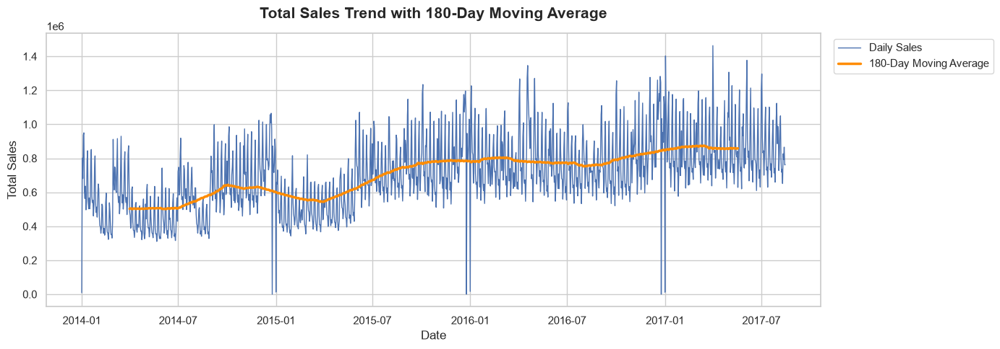

In [3]:
df_toplot = df.groupby("date")["sales"].sum().reset_index()
df_toplot["date"] = pd.to_datetime(df_toplot["date"])

df_toplot["rolling_mean"] = df_toplot["sales"].rolling(window=180, center=True).mean()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

plt.plot(df_toplot["date"], df_toplot["sales"], linewidth=1, label="Daily Sales")

plt.plot(
    df_toplot["date"],
    df_toplot["rolling_mean"],
    color="darkorange",
    linewidth=2.5,
    label="180-Day Moving Average",
)

plt.title(
    "Total Sales Trend with 180-Day Moving Average",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [4]:
coords_data = {
    "city": [
        "Quito",
        "Santo Domingo",
        "Cayambe",
        "Latacunga",
        "Riobamba",
        "Ibarra",
        "Guaranda",
        "Puyo",
        "Ambato",
        "Guayaquil",
        "Salinas",
        "Daule",
        "Babahoyo",
        "Quevedo",
        "Playas",
        "Libertad",
        "Cuenca",
        "Loja",
        "Machala",
        "Esmeraldas",
        "Manta",
        "El Carmen",
    ],
    "lat": [
        -0.2298,
        -0.2530,
        0.0428,
        -0.9315,
        -1.6635,
        0.3517,
        -1.5904,
        -1.4836,
        -1.2490,
        -2.1894,
        -2.2145,
        -1.8621,
        -1.8021,
        -1.0286,
        -2.6284,
        -2.2330,
        -2.9001,
        -3.9931,
        -3.2581,
        0.9592,
        -0.9676,
        -0.2713,
    ],
    "lon": [
        -78.5249,
        -79.1753,
        -78.1452,
        -78.6158,
        -78.6546,
        -78.1223,
        -79.0022,
        -77.9950,
        -78.6167,
        -79.8890,
        -80.9515,
        -79.9776,
        -79.5344,
        -79.4635,
        -80.3895,
        -80.9103,
        -79.0058,
        -79.2042,
        -79.9553,
        -79.6539,
        -80.7089,
        -79.4647,
    ],
}

df_coords = pd.DataFrame(coords_data)

df_agg = df.groupby("city", as_index=False)["sales"].sum()
df_agg["pct"] = df_agg["sales"] / df_agg["sales"].sum() * 100
df_toplot = df_agg.merge(df_coords, on="city", how="left")

df_toplot["label"] = [
    f"{c} ({p:.1f}%)" if p >= 5 else ""
    for c, p in zip(df_toplot["city"], df_toplot["pct"])
]
fig = px.scatter_geo(
    df_toplot,
    lat="lat",
    lon="lon",
    size="sales",
    text="label",
    hover_name="city",
    hover_data={"lat": False, "lon": False, "label": False, "pct": ":.1f"},
    size_max=40,
    title="Sales Distribution by City (% of Total Sales)",
)

fig.update_geos(
    resolution=50,
    lataxis_range=[-5.2, 2.0],
    lonaxis_range=[-81.8, -75.0],
    showcountries=True,
    showland=True,
    landcolor="#e6e6e6",
)
fig.update_layout(
    width=660,
    height=620,
    margin=dict(l=10, r=10, t=50, b=10),
)
fig.show()

NameError: name 'px' is not defined

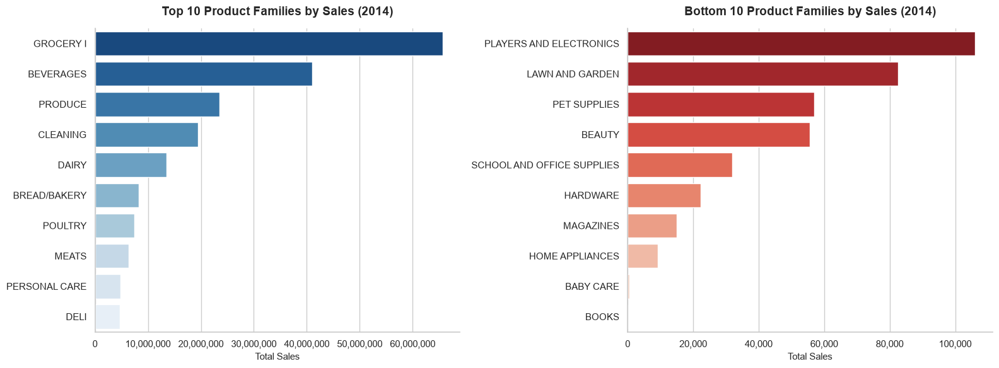

In [ ]:
YEAR = 2014

df_family = (
    df[df["year"] == YEAR]
    .groupby(["family"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)

df_family["family"] = df_family["family"].astype(str)

top_10 = df_family.head(10)
bottom_10 = df_family.tail(10)

sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_10,
    x="sales",
    y="family",
    ax=ax1,
    hue="family",
    legend=False,
    palette="Blues_r",
)
ax1.set_title(
    f"Top 10 Product Families by Sales ({YEAR})", fontsize=14, fontweight="bold", pad=15
)
ax1.set_xlabel("Total Sales", fontsize=11)
ax1.set_ylabel("")

sns.barplot(
    data=bottom_10,
    x="sales",
    y="family",
    ax=ax2,
    hue="family",
    legend=False,
    palette="Reds_r",
)
ax2.set_title(
    f"Bottom 10 Product Families by Sales ({YEAR})",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax2.set_xlabel("Total Sales", fontsize=11)
ax2.set_ylabel("")

for ax in [ax1, ax2]:
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
    )
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

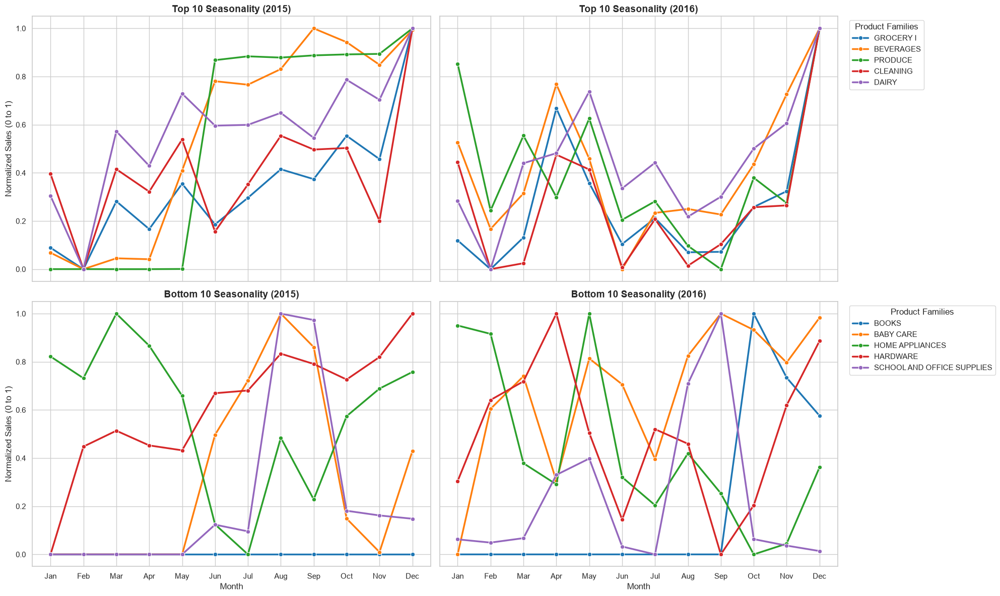

In [ ]:
target_year = 2016
previous_year = target_year - 1

df_years = df[df["year"].isin([previous_year, target_year])].copy()

yearly_totals_target = (
    df_years[df_years["year"] == target_year]
    .groupby("family")["sales"]
    .sum()
    .reset_index()
)
top_10_fams = yearly_totals_target.nlargest(5, "sales")["family"].tolist()
bottom_10_fams = yearly_totals_target.nsmallest(5, "sales")["family"].tolist()

monthly_sales = (
    df_years.groupby(["year", "family", "month"])["sales"].sum().reset_index()
)


# 4. Normalize (Min-Max Scaling per family WITHIN each year)
# 0 = worst month of the year, 1 = best month of the year
def min_max_scale(x):
    if x.max() == x.min():
        return x * 0  # Handles division by zero if sales are completely flat
    return (x - x.min()) / (x.max() - x.min())


monthly_sales["sales_normalized"] = monthly_sales.groupby(["year", "family"])[
    "sales"
].transform(min_max_scale)

top_10_monthly = monthly_sales[monthly_sales["family"].isin(top_10_fams)]
bottom_10_monthly = monthly_sales[monthly_sales["family"].isin(bottom_10_fams)]

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharex=True, sharey=True)
months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]


def plot_seasonality(ax, data, year, order, title, is_bottom_row):
    sns.lineplot(
        data=data[data["year"] == year],
        x="month",
        y="sales_normalized",
        hue="family",
        hue_order=order,
        marker="o",
        linewidth=2.5,
        ax=ax,
        palette="tab10",
    )
    ax.set_title(f"{title} ({year})", fontsize=14, fontweight="bold")

    if ax.get_subplotspec().is_first_col():
        ax.set_ylabel("Normalized Sales (0 to 1)", fontsize=12)
    else:
        ax.set_ylabel("")

    if is_bottom_row:
        ax.set_xlabel("Month", fontsize=12)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(months_labels)

    if ax.get_subplotspec().is_last_col():
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Product Families")
    else:
        if ax.get_legend():
            ax.get_legend().remove()


plot_seasonality(
    axes[0, 0], top_10_monthly, previous_year, top_10_fams, "Top 10 Seasonality", False
)
plot_seasonality(
    axes[0, 1], top_10_monthly, target_year, top_10_fams, "Top 10 Seasonality", False
)

plot_seasonality(
    axes[1, 0],
    bottom_10_monthly,
    previous_year,
    bottom_10_fams,
    "Bottom 10 Seasonality",
    True,
)
plot_seasonality(
    axes[1, 1],
    bottom_10_monthly,
    target_year,
    bottom_10_fams,
    "Bottom 10 Seasonality",
    True,
)

plt.tight_layout()
plt.show()

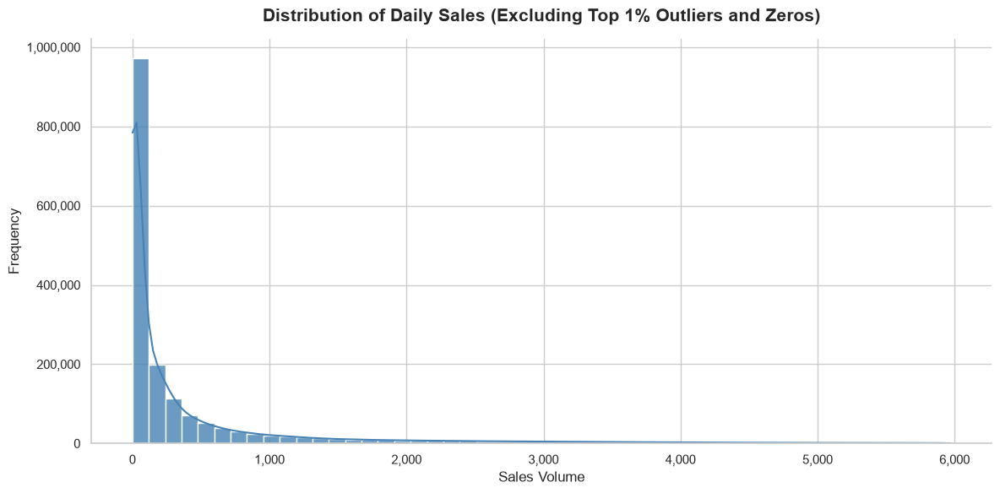

In [ ]:
upper_limit = df["sales"].quantile(0.99)
df_plot = df[(df["sales"] > 0) & (df["sales"] <= upper_limit)]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_plot,
    x="sales",
    bins=50,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
)

plt.title(
    "Distribution of Daily Sales (Excluding Top 1% Outliers and Zeros)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Sales Volume", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y)))
)

sns.despine()
plt.tight_layout()
plt.show()

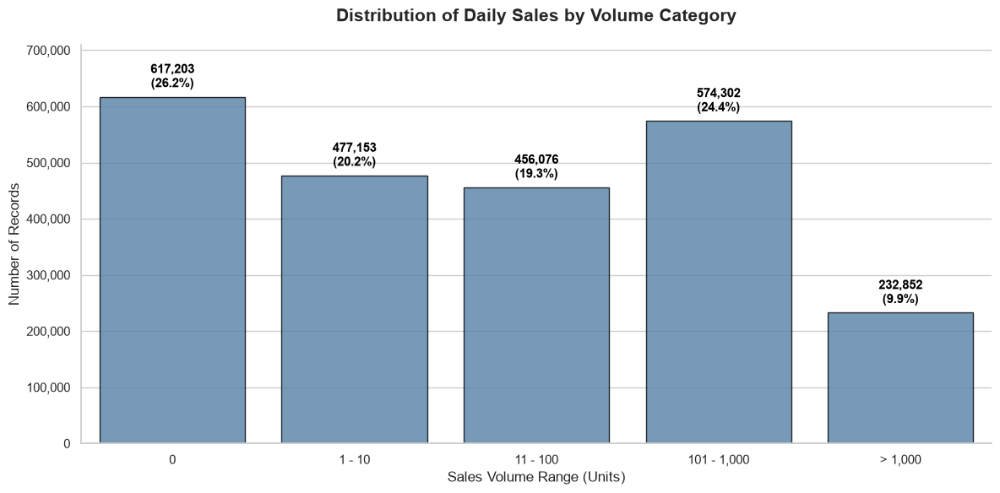

In [ ]:
bins = [-1, 0, 10, 100, 1000, np.inf]
etiquetas = ["0", "1 - 10", "11 - 100", "101 - 1,000", "> 1,000"]

df["sales_bucket"] = pd.cut(df["sales"], bins=bins, labels=etiquetas)

df_buckets = df["sales_bucket"].value_counts().reset_index()
df_buckets.columns = ["Bucket", "Count"]

df_buckets["Bucket"] = pd.Categorical(
    df_buckets["Bucket"], categories=etiquetas, ordered=True
)
df_buckets = df_buckets.sort_values("Bucket")


sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df_buckets,
    x="Bucket",
    y="Count",
    color="steelblue",
    edgecolor="black",
    alpha=0.8,
)

total_records = len(df)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        porcentaje = (height / total_records) * 100
        ax.annotate(
            f"{int(height):,}\n({porcentaje:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="black",
            xytext=(0, 5),
            textcoords="offset points",
        )

plt.title(
    "Distribution of Daily Sales by Volume Category",
    fontsize=15,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Sales Volume Range (Units)", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y))))

sns.despine()

plt.margins(y=0.15)
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("store_type")["sales"].sum().reset_index().sort_values(
    "sales", ascending=False
)

,store_type,sales
0,A,3.060229e+08
3,D,3.053157e+08
2,C,1.409568e+08
1,B,1.267673e+08
4,E,5.416316e+07


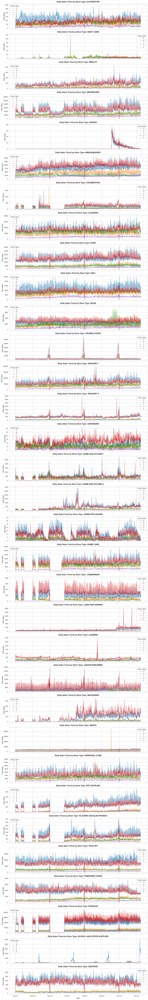

In [ ]:
target_families = ["AUTOMOTIVE", "LADIESWEAR", "PRODUCE"]
target_families = df["family"].unique()
df_filtered = df[df["family"].isin(target_families)].copy()

df_agg = (
    df_filtered.groupby(["family", "date", "store_type"])["sales"].sum().reset_index()
)
df_agg["date"] = pd.to_datetime(df_agg["date"])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(33, 1, figsize=(15, 100), sharex=True)

for i, family in enumerate(target_families):
    sns.lineplot(
        data=df_agg[df_agg["family"] == family],
        x="date",
        y="sales",
        hue="store_type",
        linewidth=1,
        palette="tab10",
        ax=axes[i],
    )

    axes[i].set_title(
        f"Daily Sales Trend by Store Type: {family}",
        fontsize=14,
        fontweight="bold",
        pad=10,
    )
    axes[i].set_ylabel("Total Sales", fontsize=12)


plt.tight_layout()
plt.show()

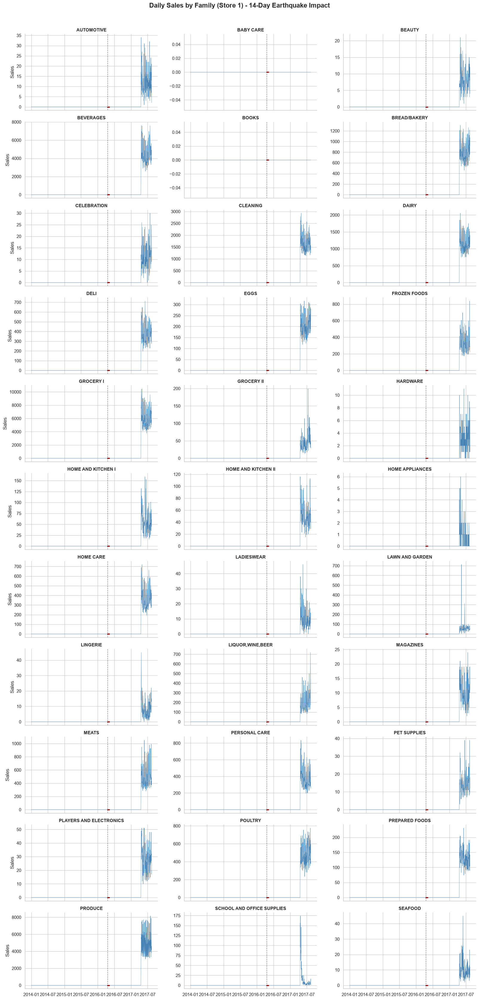

In [ ]:
df_store1 = df[df["store_nbr"] == 52].copy()
df_agg = df_store1.groupby(["family", "date"])["sales"].sum().reset_index()

sns.set_theme(style="whitegrid")
g = sns.FacetGrid(df_agg, col="family", col_wrap=3, sharey=False, height=3, aspect=1.8)


def plot_impact_window(data, **kwargs):
    ax = plt.gca()

    sns.lineplot(
        data=data, x="date", y="sales", color="steelblue", linewidth=0.5, ax=ax
    )

    impact_data = data[(data["date"] >= "2016-04-16") & (data["date"] <= "2016-05-07")]

    if not impact_data.empty:
        sns.lineplot(
            data=impact_data, x="date", y="sales", color="darkred", linewidth=2.5, ax=ax
        )

    ax.axvline(
        pd.to_datetime("2016-04-16"),
        color="black",
        linestyle="--",
        alpha=0.5,
        linewidth=1,
    )


g.map_dataframe(plot_impact_window)

g.fig.suptitle(
    "Daily Sales by Family (Store 1) - 14-Day Earthquake Impact",
    y=1.02,
    fontsize=16,
    fontweight="bold",
)
g.set_titles("{col_name}", fontweight="bold", size=11)
g.set_axis_labels("", "Sales")

plt.show()

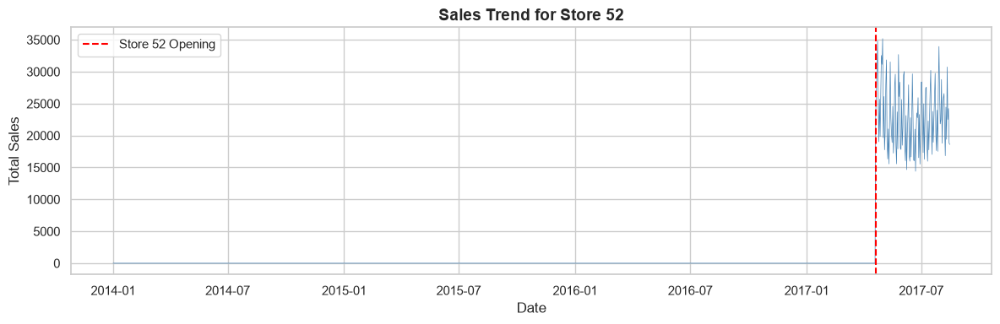

In [ ]:
data = df[df["store_nbr"] == 52].groupby(["date"])["sales"].sum().reset_index()

plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

plt.axvline(
    pd.to_datetime("2017-04-20"), color="red", linestyle="--", label="Store 52 Opening"
)

plt.title("Sales Trend for Store 52", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

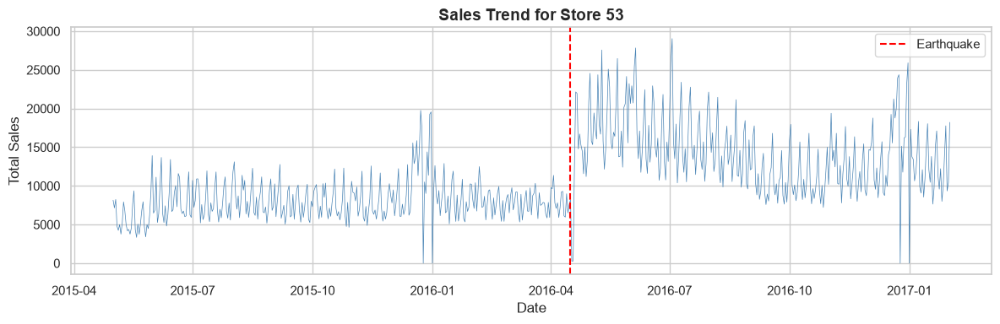

In [ ]:
STORE_NBR = 53
DATE_MIN = "2015-05-01"
DATE_MAX = "2017-02-01"

data = (
    df[
        (df["store_nbr"] == STORE_NBR)
        & (df["date"] >= DATE_MIN)
        & (df["date"] <= DATE_MAX)
    ]
    .groupby(["date"])["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

plt.axvline(
    pd.to_datetime("2016-04-16"), color="red", linestyle="--", label="Earthquake"
)

plt.title(f"Sales Trend for Store {STORE_NBR}", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

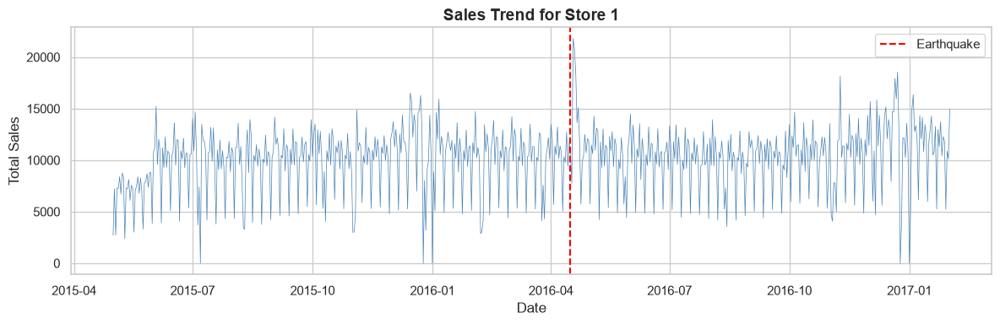

In [ ]:
STORE_NBR = 1
DATE_MIN = "2015-05-01"
DATE_MAX = "2017-02-01"

data = (
    df[
        (df["store_nbr"] == STORE_NBR)
        & (df["date"] >= DATE_MIN)
        & (df["date"] <= DATE_MAX)
    ]
    .groupby(["date"])["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

plt.axvline(
    pd.to_datetime("2016-04-16"), color="red", linestyle="--", label="Earthquake"
)

plt.title(f"Sales Trend for Store {STORE_NBR}", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

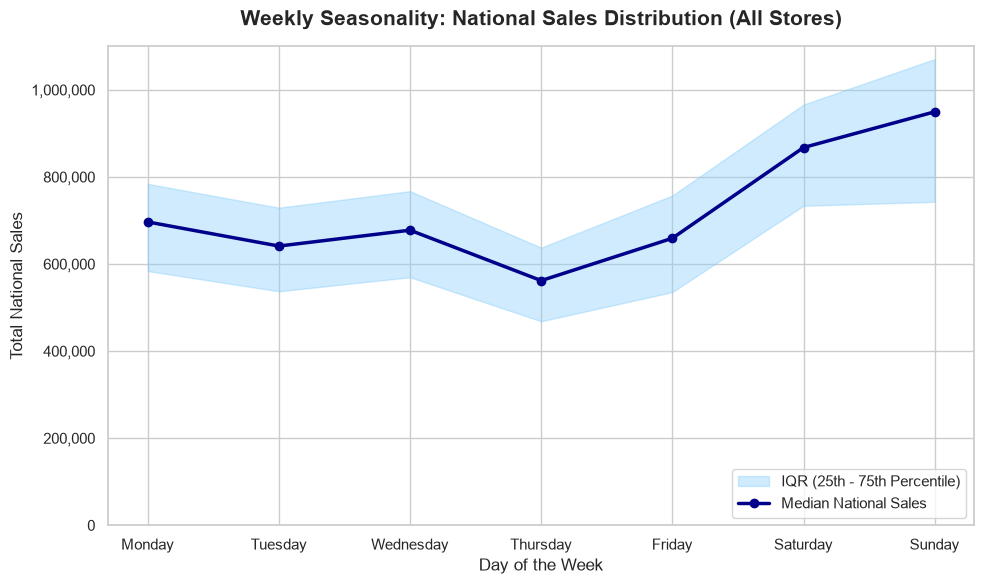

In [ ]:
df_daily_total = df.groupby(["date", "weekday"])["sales"].sum().reset_index()

weekly_stats = (
    df_daily_total.groupby("weekday")["sales"]
    .agg(
        median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

days_map = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}
weekly_stats["weekday_name"] = weekly_stats["weekday"].map(days_map)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

plt.fill_between(
    weekly_stats["weekday_name"],
    weekly_stats["q25"],
    weekly_stats["q75"],
    color="lightskyblue",
    alpha=0.4,
    label="IQR (25th - 75th Percentile)",
)

plt.plot(
    weekly_stats["weekday_name"],
    weekly_stats["median"],
    color="darkblue",
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Median National Sales",
)

plt.title(
    "Weekly Seasonality: National Sales Distribution (All Stores)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total National Sales", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.ylim(bottom=0)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

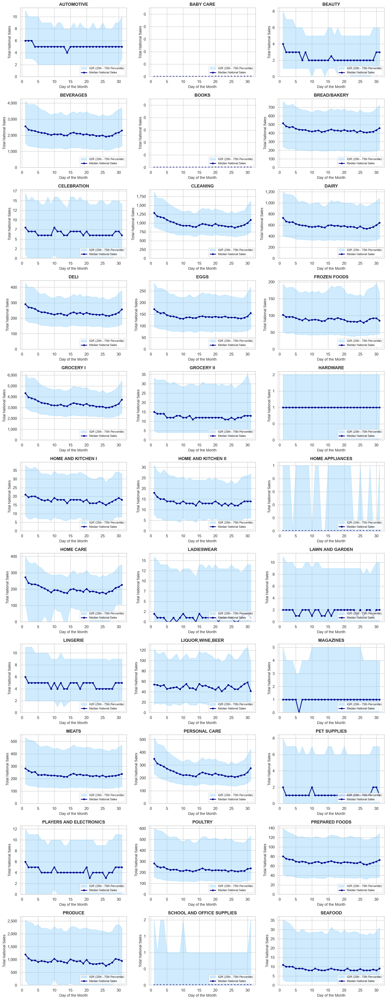

In [ ]:
families = df["family"].unique()
n_cols = 3
n_rows = (len(families) + n_cols - 1) // n_cols

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.5 * n_rows))
axes = axes.flatten()

for ax, i in zip(axes, families):
    # df_daily_total = df[(df["is_holiday"]==0) & (df["family"]==i)].groupby(["date"])["sales"].sum().reset_index()
    df_daily_total = df[(df["is_holiday"] == 0) & (df["family"] == i)].copy()

    df_daily_total["day"] = df_daily_total["date"].dt.day

    weekly_stats = (
        df_daily_total.groupby("day")["sales"]
        .agg(
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )

    ax.fill_between(
        weekly_stats["day"],
        weekly_stats["q25"],
        weekly_stats["q75"],
        color="lightskyblue",
        alpha=0.4,
        label="IQR (25th - 75th Percentile)",
    )

    ax.plot(
        weekly_stats["day"],
        weekly_stats["median"],
        color="darkblue",
        linewidth=2,
        marker="o",
        markersize=4,
        label="Median National Sales",
    )

    ax.set_title(i, fontsize=12, fontweight="bold")
    ax.set_xlabel("Day of the Month", fontsize=10)
    ax.set_ylabel("Total National Sales", fontsize=10)

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
    )
    ax.set_ylim(bottom=0)
    ax.legend(loc="lower right", fontsize=8)

for ax in axes[len(families) :]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

/var/folders/b9/tbgpz8m52snfk4vhdbmpn1hr0000gn/T/ipykernel_39832/3219036385.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


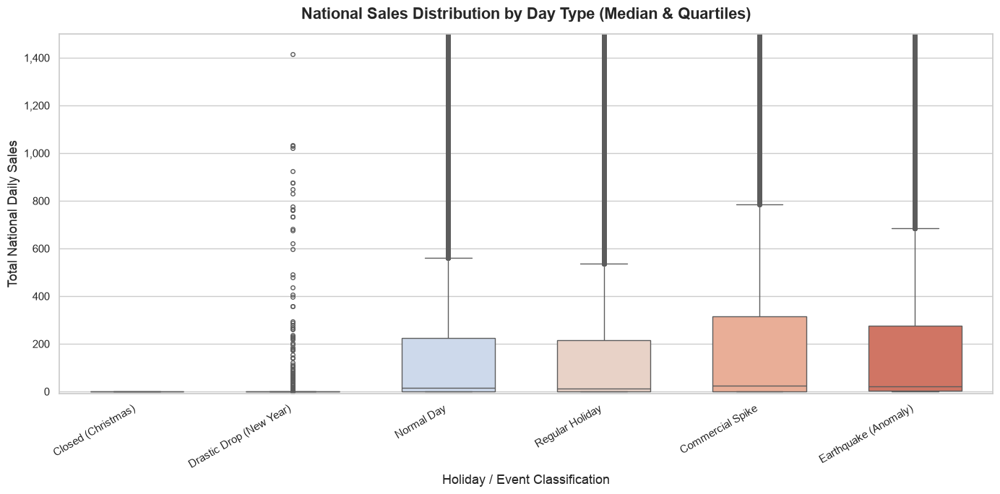

In [ ]:
cond = [
    df["is_closed"] == 1,
    df["is_drastic_drop"] == 1,
    df["is_earthquake_manabi"] == 1,
    df["is_commercial_spike"] == 1,
    df["is_regular_holiday"] == 1,
]
cat = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Earthquake (Anomaly)",
    "Commercial Spike",
    "Regular Holiday",
]

df["day_type"] = np.select(cond, cat, default="Normal Day")

orden_grafico = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Normal Day",
    "Regular Holiday",
    "Commercial Spike",
    "Earthquake (Anomaly)",
]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="day_type",
    y="sales",
    order=orden_grafico,
    palette="coolwarm",
    width=0.6,
    fliersize=4,
)

plt.title(
    "National Sales Distribution by Day Type (Median & Quartiles)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Holiday / Event Classification", fontsize=13)
plt.ylabel("Total National Daily Sales", fontsize=13)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.xticks(rotation=30, ha="right", fontsize=11)
plt.ylim(-10, 1500)

plt.tight_layout()
plt.show()

/var/folders/b9/tbgpz8m52snfk4vhdbmpn1hr0000gn/T/ipykernel_39832/2851564153.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


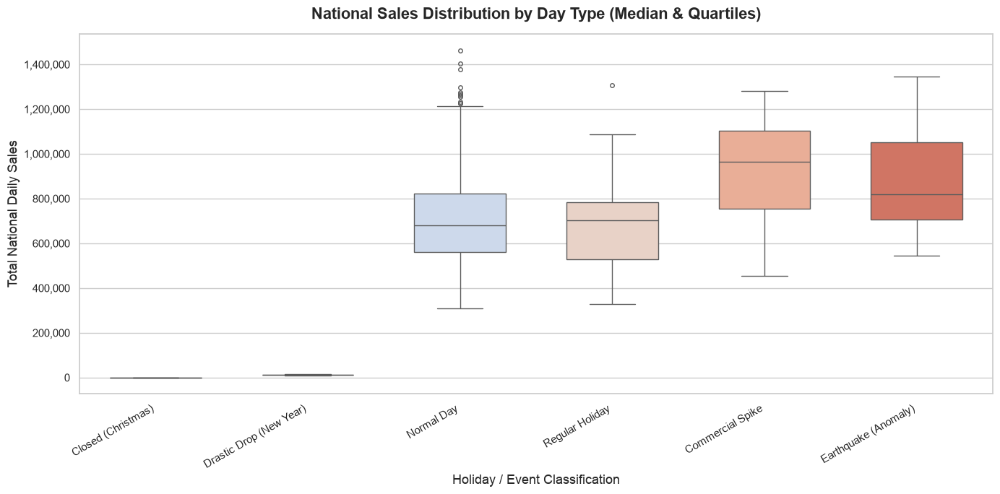

In [ ]:
df["date"] = pd.to_datetime(df["date"])


df_daily = (
    df.groupby("date")
    .agg(
        {
            "sales": "sum",
            "is_earthquake_manabi": "max",
            "is_closed": "max",
            "is_drastic_drop": "max",
            "is_commercial_spike": "max",
            "is_regular_holiday": "max",
        }
    )
    .reset_index()
)


condiciones = [
    df_daily["is_closed"] == 1,
    df_daily["is_drastic_drop"] == 1,
    df_daily["is_earthquake_manabi"] == 1,
    df_daily["is_commercial_spike"] == 1,
    df_daily["is_regular_holiday"] == 1,
]
categorias = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Earthquake (Anomaly)",
    "Commercial Spike",
    "Regular Holiday",
]

df_daily["day_type"] = np.select(condiciones, categorias, default="Normal Day")

order = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Normal Day",
    "Regular Holiday",
    "Commercial Spike",
    "Earthquake (Anomaly)",
]


sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))


sns.boxplot(
    data=df_daily,
    x="day_type",
    y="sales",
    order=order,
    palette="coolwarm",
    width=0.6,
    fliersize=4,
)

plt.title(
    "National Sales Distribution by Day Type (Median & Quartiles)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Holiday / Event Classification", fontsize=13)
plt.ylabel("Total National Daily Sales", fontsize=13)


plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.xticks(rotation=30, ha="right", fontsize=11)

plt.tight_layout()
plt.show()

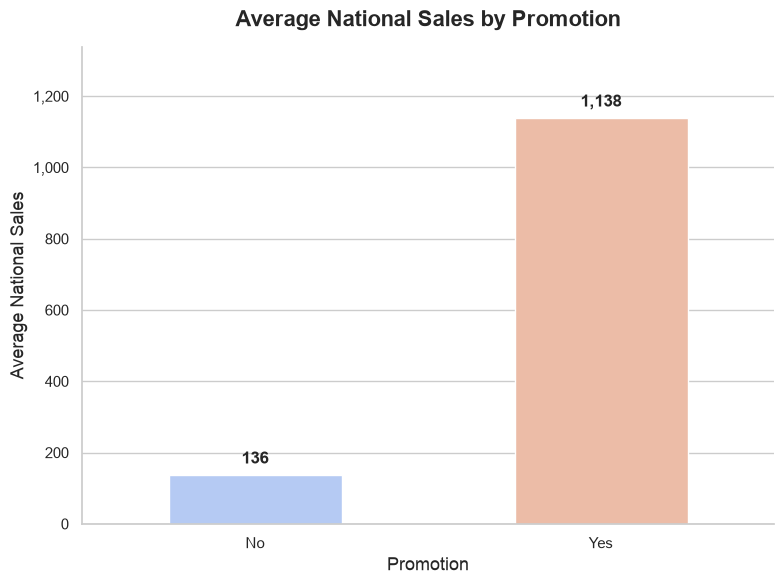

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

promotion = (df["onpromotion"] > 0).map({False: "No", True: "Yes"})

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    x=promotion,
    y=df["sales"],
    hue=promotion,
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette="coolwarm",
    width=0.5,
    errorbar=None,
    legend=False,
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
    )

plt.ylim(0, ax.get_ylim()[1] * 1.12)
plt.title(
    "Average National Sales by Promotion",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Promotion", fontsize=13)
plt.ylabel("Average National Sales", fontsize=13)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()

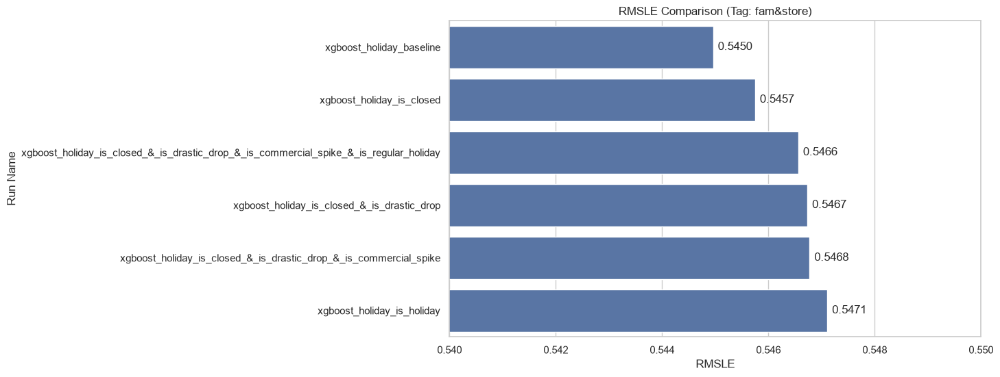

In [ ]:
mlflow.set_tracking_uri("sqlite:///../mlflow.db")

experiment = mlflow.get_experiment_by_name("Store_Sales_Forecasting")

df_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id], filter_string="tags.issue = 'holiday'"
)

plot_data = df_runs[["tags.mlflow.runName", "metrics.global_rmsle"]].dropna()
plot_data = plot_data.sort_values(by="metrics.global_rmsle", ascending=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="metrics.global_rmsle",
    y="tags.mlflow.runName",
)

plt.title("RMSLE Comparison (Tag: fam&store)")
plt.xlabel("RMSLE")
plt.ylabel("Run Name")

for i in ax.containers:
    ax.bar_label(i, fmt="%.4f", padding=5)


plt.xlim(0.54, 0.55)

plt.show()

In [ ]:
ref_date = pd.Timestamp("2016-04-16")
target_dates = pd.to_datetime(["2016-04-17", "2016-04-19"])

coords_data = {
    "city": [
        "Quito",
        "Santo Domingo",
        "Cayambe",
        "Latacunga",
        "Riobamba",
        "Ibarra",
        "Guaranda",
        "Puyo",
        "Ambato",
        "Guayaquil",
        "Salinas",
        "Daule",
        "Babahoyo",
        "Quevedo",
        "Playas",
        "Libertad",
        "Cuenca",
        "Loja",
        "Machala",
        "Esmeraldas",
        "Manta",
        "El Carmen",
    ],
    "lat": [
        -0.2298,
        -0.2530,
        0.0428,
        -0.9315,
        -1.6635,
        0.3517,
        -1.5904,
        -1.4836,
        -1.2490,
        -2.1894,
        -2.2145,
        -1.8621,
        -1.8021,
        -1.0286,
        -2.6284,
        -2.2330,
        -2.9001,
        -3.9931,
        -3.2581,
        0.9592,
        -0.9676,
        -0.2713,
    ],
    "lon": [
        -78.5249,
        -79.1753,
        -78.1452,
        -78.6158,
        -78.6546,
        -78.1223,
        -79.0022,
        -77.9950,
        -78.6167,
        -79.8890,
        -80.9515,
        -79.9776,
        -79.5344,
        -79.4635,
        -80.3895,
        -80.9103,
        -79.0058,
        -79.2042,
        -79.9553,
        -79.6539,
        -80.7089,
        -79.4647,
    ],
}

coords = (
    df[["city", "state"]]
    .drop_duplicates()
    .merge(pd.DataFrame(coords_data), on="city")
    .groupby("state", as_index=False)[["lat", "lon"]]
    .mean()
)

daily = df.groupby(["date", "state"], as_index=False)["sales"].sum()
daily["date"] = pd.to_datetime(daily["date"])

baseline = (
    daily[
        daily["date"].between(
            ref_date - pd.Timedelta(days=7), ref_date - pd.Timedelta(days=1)
        )
    ]
    .groupby("state", as_index=False)["sales"]
    .mean()
    .rename(columns={"sales": "baseline"})
)

plot_df = (
    daily[daily["date"].isin(target_dates)]
    .merge(baseline.query("baseline > 0"), on="state")
    .merge(coords, on="state")
    .sort_values("date")
)
plot_df["pct_change"] = (plot_df["sales"] / plot_df["baseline"] - 1) * 100
plot_df["abs_change"] = plot_df["pct_change"].abs()
plot_df["date_str"] = plot_df["date"].dt.strftime("%Y-%m-%d")

fig = px.scatter_geo(
    plot_df,
    lat="lat",
    lon="lon",
    color="pct_change",
    size="abs_change",
    size_max=45,
    facet_col="date_str",
    facet_col_spacing=0.04,
    hover_name="state",
    hover_data={
        "lat": False,
        "lon": False,
        "abs_change": False,
        "date_str": False,
        "pct_change": ":+.1f",
    },
    color_continuous_scale=["#800026", "#e31a1c", "#f7f7f7", "#238b45", "#00441b"],
    range_color=[-40, 40],
    title="Sales % Change vs Prior 7d Mean",
)

for g in ["geo", "geo2"]:
    fig.add_scattergeo(
        lat=[0.382],
        lon=[-79.922],
        geo=g,
        mode="markers+text",
        text=["Epicenter"],
        textposition="middle left",
        marker=dict(symbol="star", size=14, color="black"),
        showlegend=False,
        hoverinfo="text",
    )

fig.update_geos(
    resolution=50,
    lataxis_range=[-5.2, 2.0],
    lonaxis_range=[-81.8, -75.0],
    showcountries=True,
    showland=True,
    landcolor="#e6e6e6",
)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(
    width=1100,
    height=560,
    margin=dict(l=10, r=10, t=70, b=10),
    coloraxis_colorbar=dict(title="% Change", ticksuffix="%"),
)
fig.show()

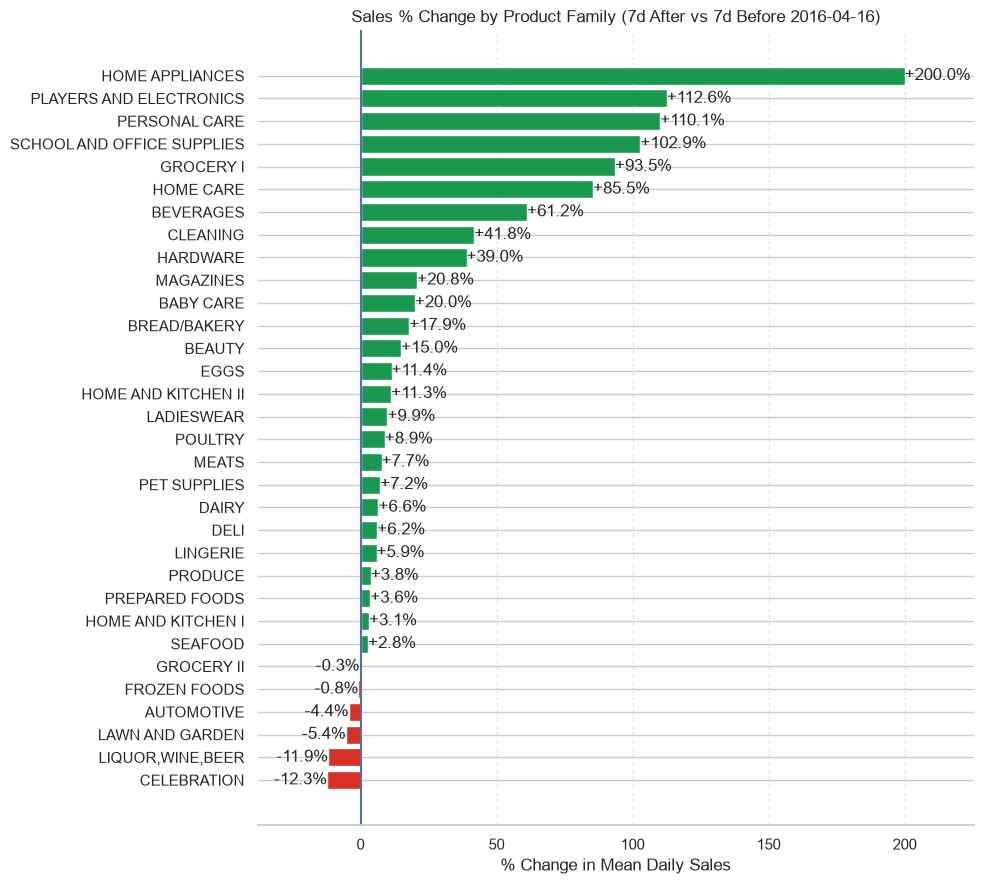

In [ ]:
ref_date = pd.Timestamp("2016-04-16")
window_days = 7

daily_fam = (
    df.assign(date=pd.to_datetime(df["date"]))
    .groupby(["date", "family"], as_index=False)["sales"]
    .sum()
)

pre = (
    daily_fam[
        daily_fam["date"].between(
            ref_date - pd.Timedelta(days=window_days), ref_date - pd.Timedelta(days=1)
        )
    ]
    .groupby("family")["sales"]
    .mean()
)

post = (
    daily_fam[
        daily_fam["date"].between(
            ref_date + pd.Timedelta(days=1), ref_date + pd.Timedelta(days=window_days)
        )
    ]
    .groupby("family")["sales"]
    .mean()
)

comp = pd.DataFrame({"pre": pre, "post": post}).query("pre > 0")
comp["pct_change"] = (comp["post"] / comp["pre"] - 1) * 100
comp = comp.sort_values("pct_change")

colors = ["#1a9850" if x > 0 else "#d73027" for x in comp["pct_change"]]

fig, ax = plt.subplots(figsize=(10, 9))
bars = ax.barh(comp.index, comp["pct_change"], color=colors)

ax.axvline(0)
ax.bar_label(bars, fmt="%+.1f%%")
ax.margins(x=0.12)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.set_title(
    f"Sales % Change by Product Family ({window_days}d After vs {window_days}d Before {ref_date.date()})"
)
ax.set_xlabel("% Change in Mean Daily Sales")
plt.tight_layout()
plt.show()

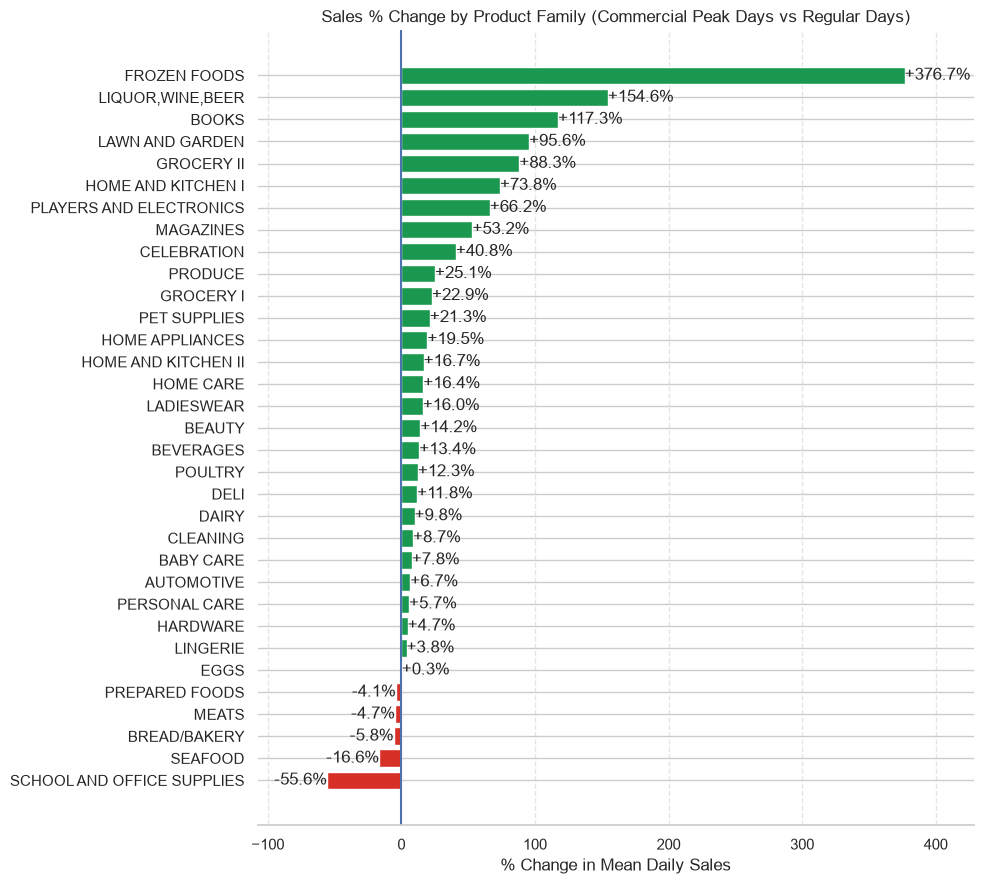

In [ ]:
daily_fam = df.groupby(["date", "family"], as_index=False).agg(
    sales=("sales", "sum"), is_peak=("is_commercial_spike", "max")
)

normal = daily_fam[daily_fam["is_peak"] == 0].groupby("family")["sales"].mean()

peak = daily_fam[daily_fam["is_peak"] == 1].groupby("family")["sales"].mean()

comp = pd.DataFrame({"normal": normal, "peak": peak}).query("normal > 0")
comp["pct_change"] = (comp["peak"] / comp["normal"] - 1) * 100
comp = comp.sort_values("pct_change")

colors = ["#1a9850" if x > 0 else "#d73027" for x in comp["pct_change"]]

fig, ax = plt.subplots(figsize=(10, 9))
bars = ax.barh(comp.index, comp["pct_change"], color=colors)

ax.axvline(0)
ax.bar_label(bars, fmt="%+.1f%%")
ax.margins(x=0.12)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.set_title("Sales % Change by Product Family (Commercial Peak Days vs Regular Days)")
ax.set_xlabel("% Change in Mean Daily Sales")
plt.tight_layout()
plt.show()

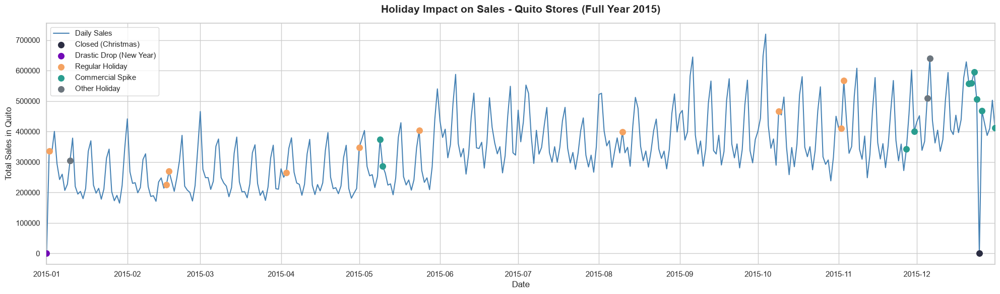

In [ ]:
YEAR = 2015

df_quito = df[df["city"] == "Quito"].copy()

conditions = [
    df_quito["is_closed"] == 1,
    df_quito["is_drastic_drop"] == 1,
    df_quito["is_earthquake_manabi"] == 1,
    df_quito["is_commercial_spike"] == 1,
    df_quito["is_regular_holiday"] == 1,
    df_quito["is_holiday"] == 1,
]
choices = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Earthquake (Anomaly)",
    "Commercial Spike",
    "Regular Holiday",
    "Other Holiday",
]
df_quito["holiday_category"] = np.select(conditions, choices, default="Normal Day")

df_daily_sales = df_quito.groupby(["date", "year"])["sales"].sum().reset_index()

df_holiday_info = df_quito[df_quito["holiday_category"] != "Normal Day"][
    ["date", "year", "holiday_category"]
].drop_duplicates(subset=["date"])

df_plot = df_daily_sales.merge(df_holiday_info, on=["date", "year"], how="left")
df_plot = df_plot[df_plot["year"] == YEAR].copy()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(20, 6))

sns.lineplot(
    data=df_plot,
    x="date",
    y="sales",
    color="steelblue",
    linewidth=1.5,
    label="Daily Sales",
)

category_palette = {
    "Closed (Christmas)": "#2b2d42",
    "Drastic Drop (New Year)": "#7209b7",
    "Regular Holiday": "#f4a261",
    "Commercial Spike": "#2a9d8f",
    "Earthquake (Anomaly)": "#d62828",
    "Other Holiday": "#6c757d",
}

df_holidays = df_plot[df_plot["holiday_category"].notna()]

for category, color in category_palette.items():
    subset = df_holidays[df_holidays["holiday_category"] == category]
    if not subset.empty:
        plt.scatter(
            subset["date"],
            subset["sales"],
            color=color,
            s=70,
            zorder=5,
            label=category,
        )

plt.title(
    f"Holiday Impact on Sales - Quito Stores (Full Year {YEAR})",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales in Quito", fontsize=12)

plt.xlim(df_plot["date"].min(), df_plot["date"].max())
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

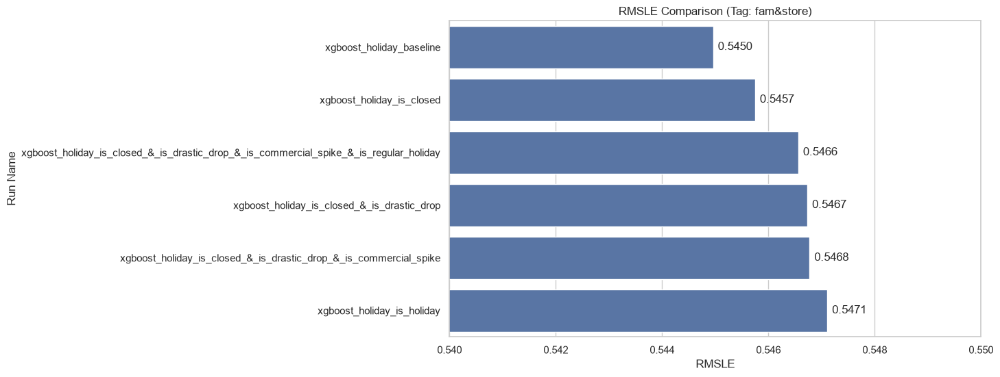

In [ ]:
mlflow.set_tracking_uri("sqlite:///../mlflow.db")

experiment = mlflow.get_experiment_by_name("Store_Sales_Forecasting")

df_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id], filter_string="tags.issue = 'holiday'"
)

plot_data = df_runs[["tags.mlflow.runName", "metrics.global_rmsle"]].dropna()
plot_data = plot_data.sort_values(by="metrics.global_rmsle", ascending=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="metrics.global_rmsle",
    y="tags.mlflow.runName",
)

plt.title("RMSLE Comparison (Tag: fam&store)")
plt.xlabel("RMSLE")
plt.ylabel("Run Name")

for i in ax.containers:
    ax.bar_label(i, fmt="%.4f", padding=5)


plt.xlim(0.54, 0.55)

plt.show()

In [ ]:
# MAIN PARAMETERS
ACTIVE_MODEL = "linear_regression"

# linear_regression, xgboost

NUMERIC_SKEWED_FEATURES = [
    "sales_lag15",
    "sales_lag21",
    "sales_lag364",
    # "sales_lag365",
]
NUMERIC_NORMAL_FEATURES = []

TIER_FEATURES = []
CATEGORICAL_FEATURES = []
TARGET_ENCODER = False

TARGET = "sales"

COLUMNS_TO_KEEP = ["date", "family", "store_nbr", "is_int_sales"]

CUTOFFS_STR = ["2017-07-15", "2017-04-15", "2017-01-15", "2016-09-15"]
CUTOFFS_DATETIME = pd.to_datetime(CUTOFFS_STR)

HORIZON = 15

ISSUE_NAME = "lags"
VERSION_NAME = "[15-21]+30,60,364,365"

PATH_TRAIN_DF = "../data/processed/df_train.parquet"

df = pd.read_parquet(PATH_TRAIN_DF)

cutoff_date = max(CUTOFFS_STR)
df_train = df[df["date"] <= cutoff_date].copy()

y_train_eda = np.log1p(df_train["sales"])
X_train_eda = df_train[NUMERIC_SKEWED_FEATURES].copy()

for col in NUMERIC_SKEWED_FEATURES:
    X_train_eda[col] = np.log1p(X_train_eda[col])

X_train_sm = sm.add_constant(X_train_eda)
model_sm = sm.OLS(y_train_eda, X_train_sm).fit()

print(model_sm.summary2())

                   Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.895       
Dependent Variable: sales            AIC:                5866302.2244
Date:               2026-11-18 17:43 BIC:                5866352.8222
No. Observations:   2302344          Log-Likelihood:     -2.9331e+06 
Df Model:           3                F-statistic:        6.575e+06   
Df Residuals:       2302340          Prob (F-statistic): 0.00        
R-squared:          0.895            Scale:              0.74833     
-----------------------------------------------------------------------
                Coef.    Std.Err.      t       P>|t|    [0.025   0.975]
-----------------------------------------------------------------------
const           0.1593     0.0009   181.2836   0.0000   0.1576   0.1610
sales_lag15     0.4332     0.0007   651.6649   0.0000   0.4319   0.4345
sales_lag21     0.4014     0.0007   579.9367   0.0000   0.4001   0.4028
sales_lag364    0.1358     

In [ ]:
vif_data = pd.DataFrame()
vif_data["Variable"] = X_train_sm.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

       Variable        VIF
2   sales_lag21  10.596287
1   sales_lag15   9.761833
3  sales_lag364   4.113421
0         const   1.000000


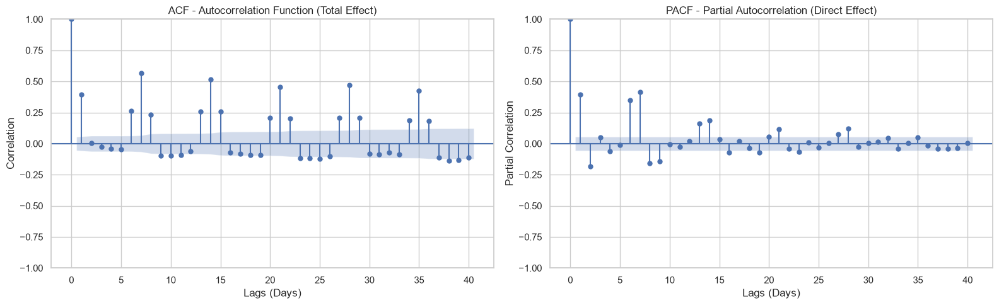

In [ ]:
single_series = df_train[
    (df_train["store_nbr"] == 44) & (df_train["family"] == "GROCERY I")
].set_index("date")["sales"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(single_series, lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title("ACF - Autocorrelation Function (Total Effect)")
axes[0].set_xlabel("Lags (Days)")
axes[0].set_ylabel("Correlation")

plot_pacf(single_series, lags=40, ax=axes[1], alpha=0.05)
axes[1].set_title("PACF - Partial Autocorrelation (Direct Effect)")
axes[1].set_xlabel("Lags (Days)")
axes[1].set_ylabel("Partial Correlation")

plt.tight_layout()
plt.show()

In [ ]:
PATH_RESULTS = "../artifacts/predictions/pred_xgboost_time_year.parquet"
results = pd.read_parquet(PATH_RESULTS)
results.head()

,sales_lag15,sales_lag16,sales_lag17,sales_lag18,sales_lag19,sales_lag20,sales_lag364,year,date,family,store_nbr,is_int_sales,cutoff,y_true,y_pred,forecast_step
1295,11.0,1.0,2.0,4.0,3.0,4.0,2.0,2017.0,2017-07-15,AUTOMOTIVE,1,True,2017-07-15,6.0,3.0,1
1296,7.0,11.0,1.0,2.0,4.0,3.0,2.0,2017.0,2017-07-16,AUTOMOTIVE,1,True,2017-07-15,2.0,3.0,2
1297,4.0,7.0,11.0,1.0,2.0,4.0,3.0,2017.0,2017-07-17,AUTOMOTIVE,1,True,2017-07-15,2.0,3.0,3
1298,0.0,4.0,7.0,11.0,1.0,2.0,9.0,2017.0,2017-07-18,AUTOMOTIVE,1,True,2017-07-15,3.0,4.0,4
1299,5.0,0.0,4.0,7.0,11.0,1.0,3.0,2017.0,2017-07-19,AUTOMOTIVE,1,True,2017-07-15,7.0,3.0,5


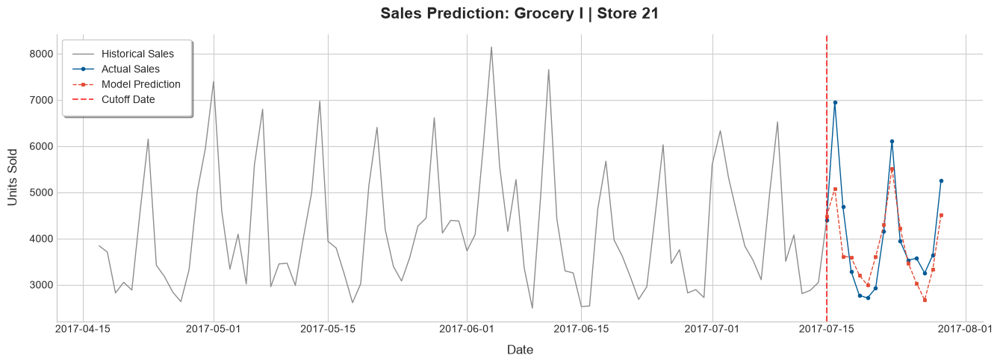

In [ ]:
plot_predictions(
    df=df,
    df_results=results,
    family_name="GROCERY I",
    store_nbr_name=21,
    cutoff="2017-07-15",
    root_artifacts=None,
)